In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12,6)

In [2]:
data = pd.read_csv("/content/Phishing_Legitimate_full.csv")

In [3]:
float_cols = data.select_dtypes('float64').columns
for c in float_cols:
    data[c] = data[c].astype('float32')

int_cols = data.select_dtypes('int64').columns
for c in int_cols:
    data[c] = data[c].astype('int32')

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  10000 non-null  int32  
 1   NumDots                             10000 non-null  int32  
 2   SubdomainLevel                      10000 non-null  int32  
 3   PathLevel                           10000 non-null  int32  
 4   UrlLength                           10000 non-null  int32  
 5   NumDash                             10000 non-null  int32  
 6   NumDashInHostname                   10000 non-null  int32  
 7   AtSymbol                            10000 non-null  int32  
 8   TildeSymbol                         10000 non-null  int32  
 9   NumUnderscore                       10000 non-null  int32  
 10  NumPercent                          10000 non-null  int32  
 11  NumQueryComponents                  10000 

In [4]:
data.rename(columns={'CLASS_LABEL': 'labels'}, inplace=True)

In [5]:
data.sample(5)

,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,NumPercent,NumQueryComponents,NumAmpersand,NumHash,NumNumericChars,NoHttps,RandomString,IpAddress,DomainInSubdomains,DomainInPaths,HttpsInHostname,HostnameLength,PathLength,QueryLength,DoubleSlashInPath,NumSensitiveWords,EmbeddedBrandName,PctExtHyperlinks,PctExtResourceUrls,ExtFavicon,InsecureForms,RelativeFormAction,ExtFormAction,AbnormalFormAction,PctNullSelfRedirectHyperlinks,FrequentDomainNameMismatch,FakeLinkInStatusBar,RightClickDisabled,PopUpWindow,SubmitInfoToEmail,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,labels
7223,7224,2,1,0,74,0,0,0,0,0,0,4,3,0,9,1,0,0,0,0,0,24,1,41,0,0,0,0.007937,0.000000,0,1,0,0,0,0.000000,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0
2620,2621,2,0,2,44,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,9,28,0,0,0,1,1.000000,1.000000,0,1,0,0,0,0.000000,1,0,0,0,0,1,0,0,1,1,-1,1,-1,-1,1
9743,9744,2,1,3,45,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,20,18,0,0,0,0,0.504505,0.525641,0,1,0,1,0,0.027027,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0
9518,9519,2,1,3,50,0,0,0,0,0,0,0,0,0,5,1,1,0,0,0,0,24,19,0,0,0,0,0.217949,0.100000,0,0,0,0,0,0.012821,0,0,0,0,1,0,0,0,1,1,0,1,1,1,0
7435,7436,4,1,2,87,0,0,0,0,0,0,1,0,0,4,1,0,0,0,1,0,28,34,17,0,0,0,0.500000,0.636364,0,1,0,0,0,0.000000,0,0,0,0,0,0,0,0,1,-1,-1,1,0,0,0


In [6]:
data.describe()

,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,NumPercent,NumQueryComponents,NumAmpersand,NumHash,NumNumericChars,NoHttps,RandomString,IpAddress,DomainInSubdomains,DomainInPaths,HttpsInHostname,HostnameLength,PathLength,QueryLength,DoubleSlashInPath,NumSensitiveWords,EmbeddedBrandName,PctExtHyperlinks,PctExtResourceUrls,ExtFavicon,InsecureForms,RelativeFormAction,ExtFormAction,AbnormalFormAction,PctNullSelfRedirectHyperlinks,FrequentDomainNameMismatch,FakeLinkInStatusBar,RightClickDisabled,PopUpWindow,SubmitInfoToEmail,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,labels
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.0,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,2.445100,0.586800,3.300300,70.264100,1.818000,0.138900,0.000300,0.013100,0.32320,0.073800,0.458600,0.277200,0.002300,5.810300,0.988800,0.52520,0.017200,0.022200,0.428900,0.0,18.82430,35.564900,8.606500,0.000900,0.109300,0.057100,0.241334,0.392932,0.167200,0.844000,0.248700,0.1018,0.057600,0.136136,0.215300,0.005500,0.014000,0.004900,0.128800,0.339600,0.03220,0.030400,0.956600,0.020200,0.353300,0.793200,0.173400,0.314100,0.500000
std,2886.89568,1.346836,0.751214,1.863241,33.369877,3.106258,0.545744,0.017319,0.113709,1.11466,0.622248,1.344793,1.117356,0.047906,9.617877,0.105241,0.49939,0.130023,0.147341,0.494944,0.0,8.11654,24.588502,24.313053,0.029988,0.368737,0.232045,0.342363,0.387295,0.373173,0.362873,0.432281,0.3024,0.232997,0.312426,0.411051,0.073961,0.117496,0.069832,0.334995,0.473597,0.17654,0.171694,0.248037,0.820036,0.888908,0.521019,0.755771,0.897843,0.500025
min,1.00000,1.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,4.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000
25%,2500.75000,2.000000,0.000000,2.000000,48.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,0.000000,0.000000,0.000000,0.0,14.00000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.030303,0.000000,1.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,-1.000000,-1.000000,1.000000,0.000000,-1.000000,0.000000
50%,5000.50000,2.000000,1.000000,3.000000,62.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.00000,0.000000,0.000000,0.000000,0.0,18.00000,30.000000,0.000000,0.000000,0.000000,0.000000,0.071429,0.247511,0.000000,1.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.500000
75%,7500.25000,3.000000,1.000000,4.000000,84.000000,2.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,8.000000,1.000000,1.00000,0.000000,0.000000,1.000000,0.0,22.00000,48.000000,0.000000,0.000000,0.000000,0.000000,0.315874,0.785714,0.000000,1.000000,0.000000,0.0000,0.000000,0.047619,0.000000,0.000000,0.000000,0.000

<Axes: xlabel='labels'>

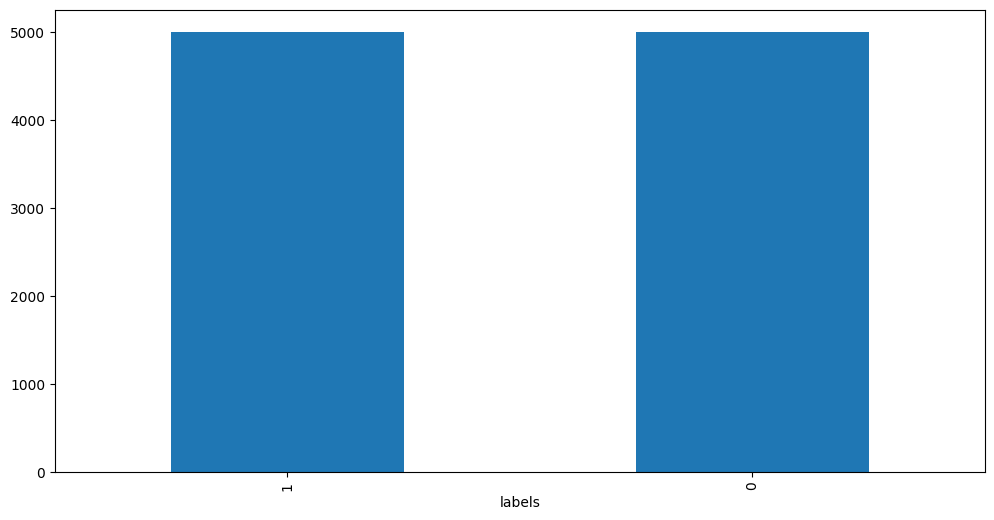

In [7]:

data['labels'].value_counts().plot(kind='bar')

In [8]:
def corr_heatmap(data, idx_s, idx_e):
    y = data['labels']
    temp = data.iloc[:, idx_s:idx_e]
    if 'id' in temp.columns:
        del temp['id']
    temp['labels'] = y
    sns.heatmap(temp.corr(), annot=True, fmt='.2f')
    plt.show()

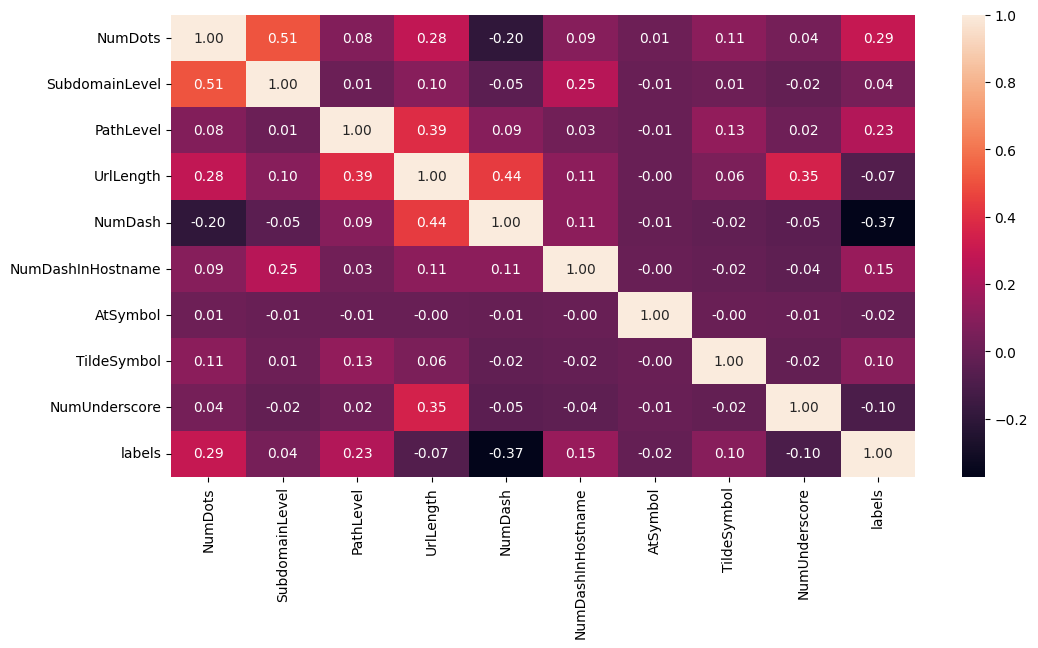

In [9]:
corr_heatmap(data, 0, 10)

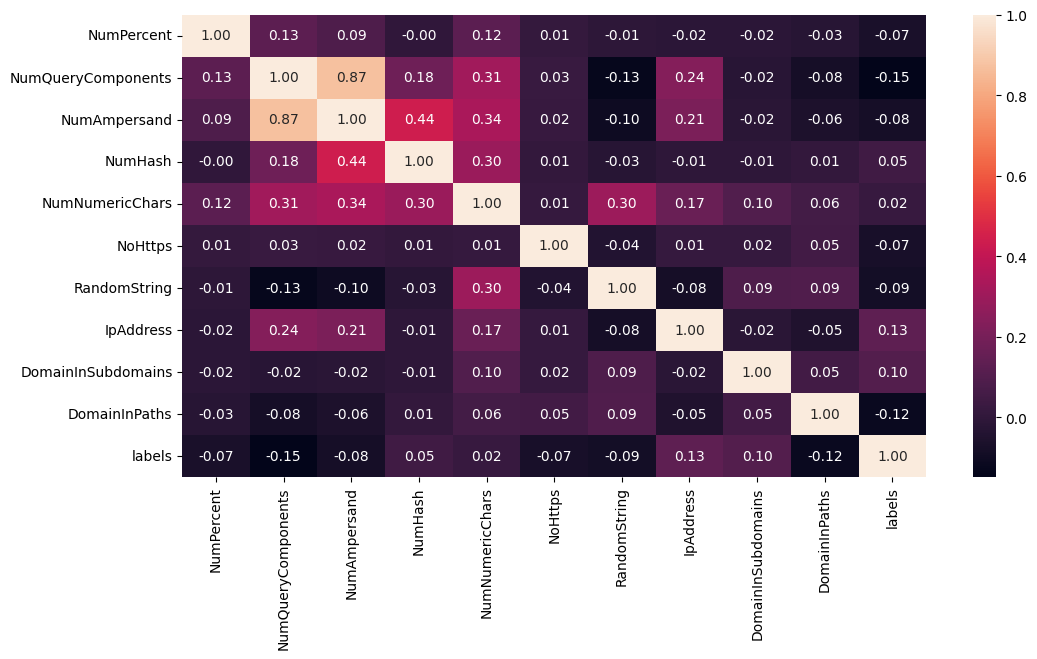

In [10]:
corr_heatmap(data, 10, 20)

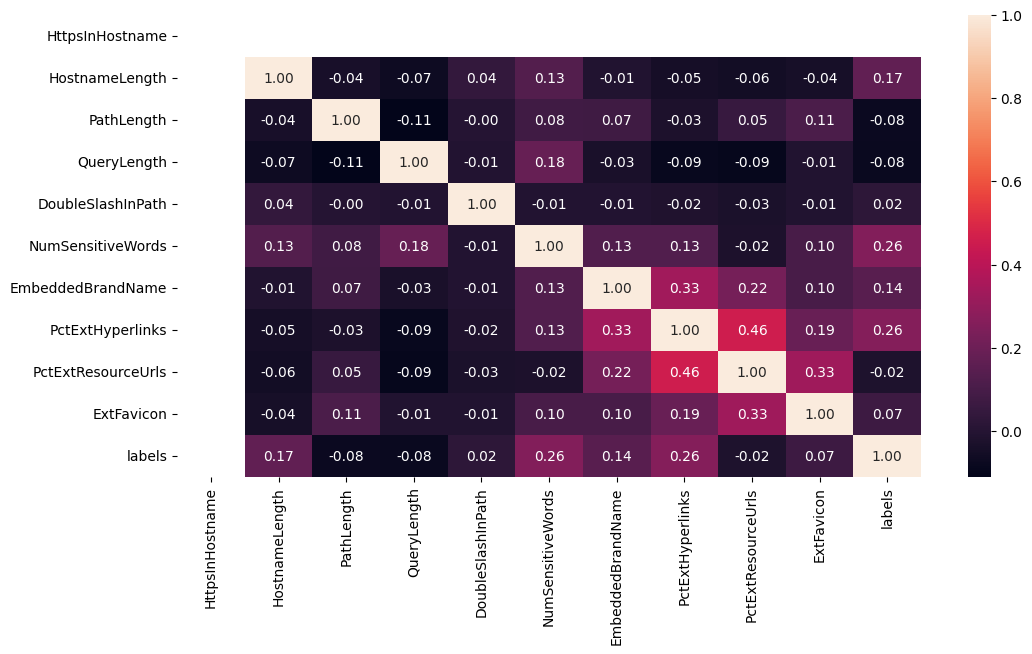

In [11]:
corr_heatmap(data, 20, 30)

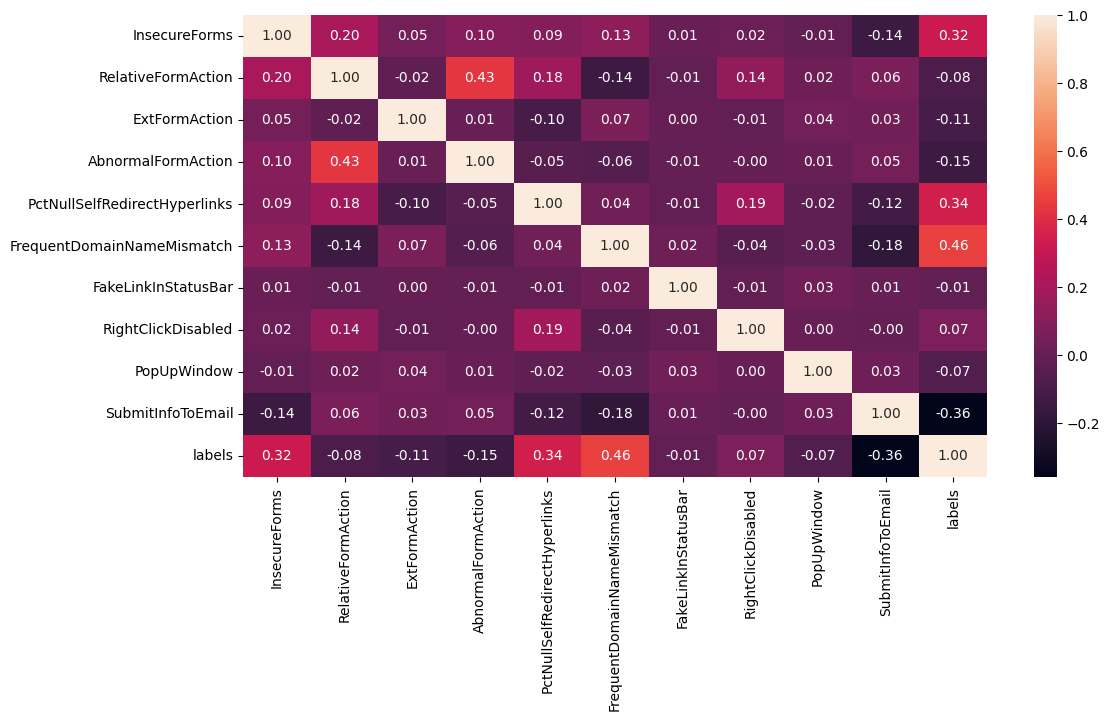

In [12]:
corr_heatmap(data, 30, 40)

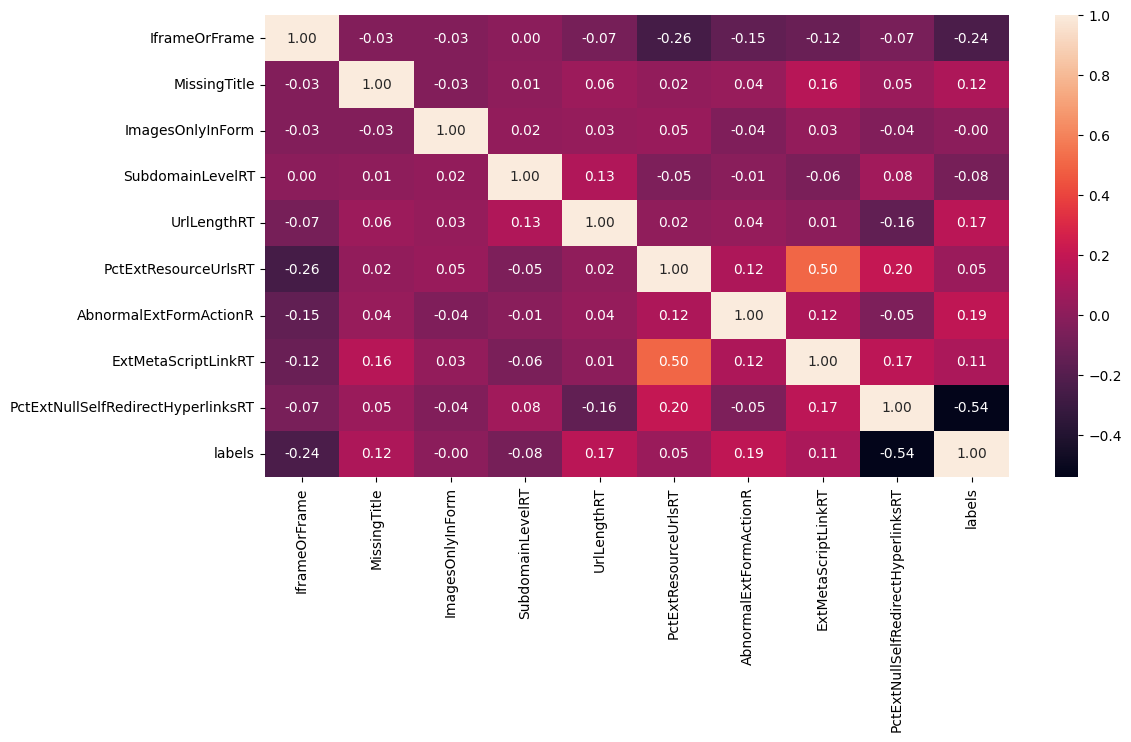

In [13]:
corr_heatmap(data, 40, 50)

In [14]:
from sklearn.feature_selection import mutual_info_classif

In [15]:
X = data.drop(['id', 'labels'], axis=1)
y = data['labels']

In [16]:
discrete_features = X.dtypes == int

In [17]:
mi_scores = mutual_info_classif(X, y, discrete_features=discrete_features)
mi_scores = pd.Series(mi_scores, name='MI Scores', index=X.columns)
mi_scores = mi_scores.sort_values(ascending=False)
mi_scores

,MI Scores
PctExtHyperlinks,0.466877
PctExtResourceUrls,0.294830
PctNullSelfRedirectHyperlinks,0.233348
PctExtNullSelfRedirectHyperlinksRT,0.210247
NumNumericChars,0.131740
FrequentDomainNameMismatch,0.127419
ExtMetaScriptLinkRT,0.119248
NumDash,0.116043
SubmitInfoToEmail,0.074254
PathLevel,0.062938


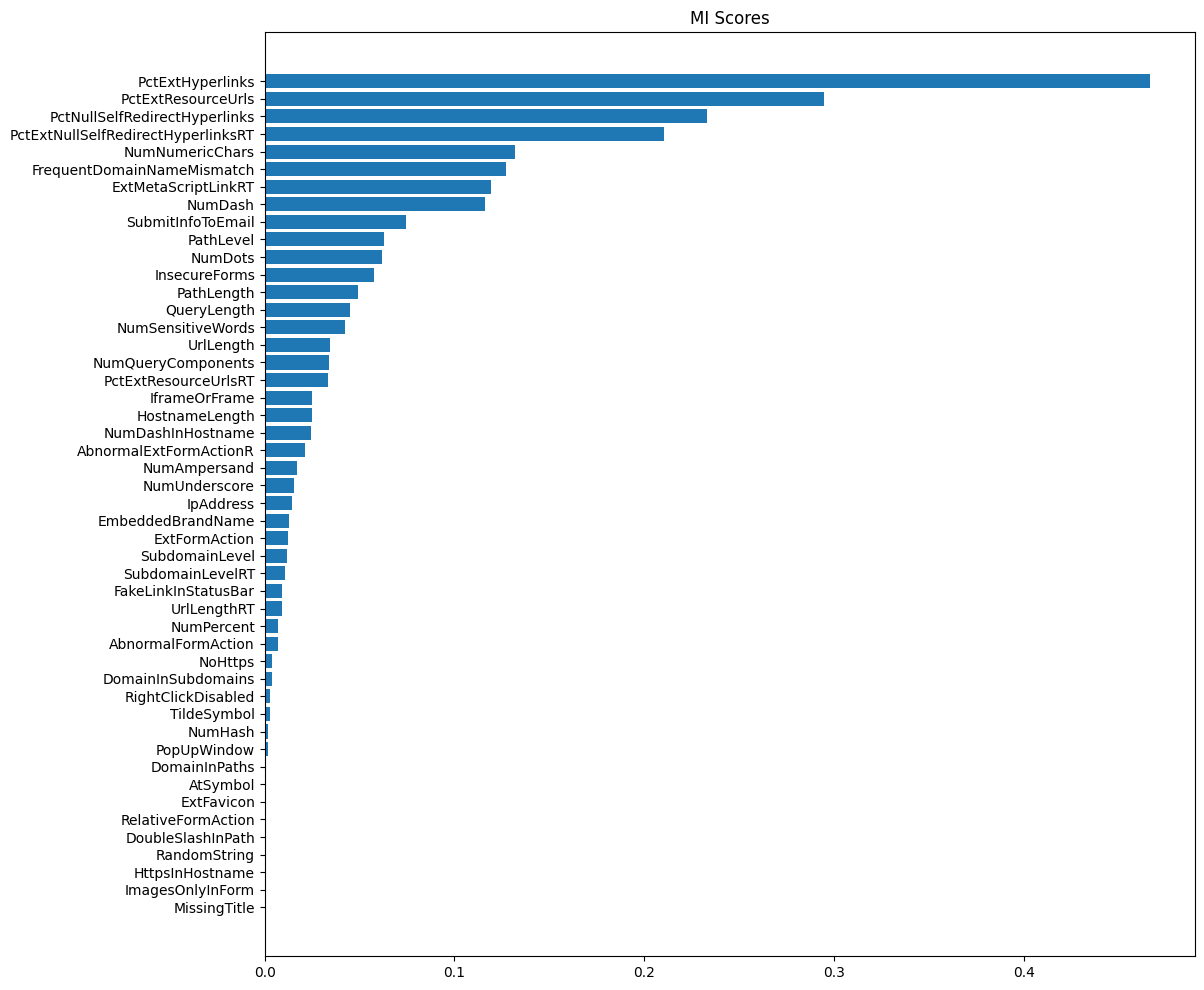

In [18]:
def plot_mi_scores(scores):
    scores = scores.sort_values(ascending=True)
    width = np.arange(len(scores))
    ticks = list(scores.index)
    plt.barh(width, scores)
    plt.yticks(width, ticks)
    plt.title("MI Scores")

plt.figure(dpi=100, figsize=(12,12))
plot_mi_scores(mi_scores)

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [22]:
def train_logistic(data, top_n):
    top_n_features = mi_scores.sort_values(ascending=False).head(top_n).index.tolist()
    X = data[top_n_features]
    y = data['labels']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

    lr = LogisticRegression(max_iter=10000)
    lr.fit(X_train, y_train)

    y_pred = lr.predict(X_test)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)

    return precision, recall, f1, accuracy

In [23]:
arr = []
for i in range(20,51,1):
    precision, recall, f1, accuracy = train_logistic(data, i)
    print("Performance for Logistic Model with Top {} features is precision : {}, recall : {}, f1 score : {}, accuracy : {}".format(i, precision, recall, f1, accuracy))
    arr.append([i, precision, recall, f1, accuracy])

Performance for Logistic Model with Top 20 features is precision : 0.9205426356589147, recall : 0.9378084896347483, f1 score : 0.9290953545232273, accuracy : 0.9275
Performance for Logistic Model with Top 21 features is precision : 0.9137596899224806, recall : 0.935515873015873, f1 score : 0.9245098039215687, accuracy : 0.923
Performance for Logistic Model with Top 22 features is precision : 0.9178605539637058, recall : 0.9449360865290068, f1 score : 0.9312015503875969, accuracy : 0.929
Performance for Logistic Model with Top 23 features is precision : 0.9213592233009709, recall : 0.9405351833498513, f1 score : 0.9308484551250613, accuracy : 0.9295
Performance for Logistic Model with Top 24 features is precision : 0.9050880626223092, recall : 0.9438775510204082, f1 score : 0.9240759240759241, accuracy : 0.924
Performance for Logistic Model with Top 25 features is precision : 0.9343137254901961, recall : 0.9361493123772102, f1 score : 0.9352306182531894, accuracy : 0.934
Performance for

In [24]:
df = pd.DataFrame(arr, columns=['num_of_features', 'precision', 'recall', 'f1_score', 'accuracy'])
df

,num_of_features,precision,recall,f1_score,accuracy
0,20,0.920543,0.937808,0.929095,0.9275
1,21,0.913760,0.935516,0.924510,0.9230
2,22,0.917861,0.944936,0.931202,0.9290
3,23,0.921359,0.940535,0.930848,0.9295
4,24,0.905088,0.943878,0.924076,0.9240
5,25,0.934314,0.936149,0.935231,0.9340
6,26,0.913300,0.933535,0.923307,0.9230
7,27,0.916667,0.927711,0.922156,0.9220
8,28,0.921687,0.930091,0.925870,0.9265
9,29,0.929212,0.949084,0.939043,0.9395


<Axes: xlabel='num_of_features', ylabel='precision'>

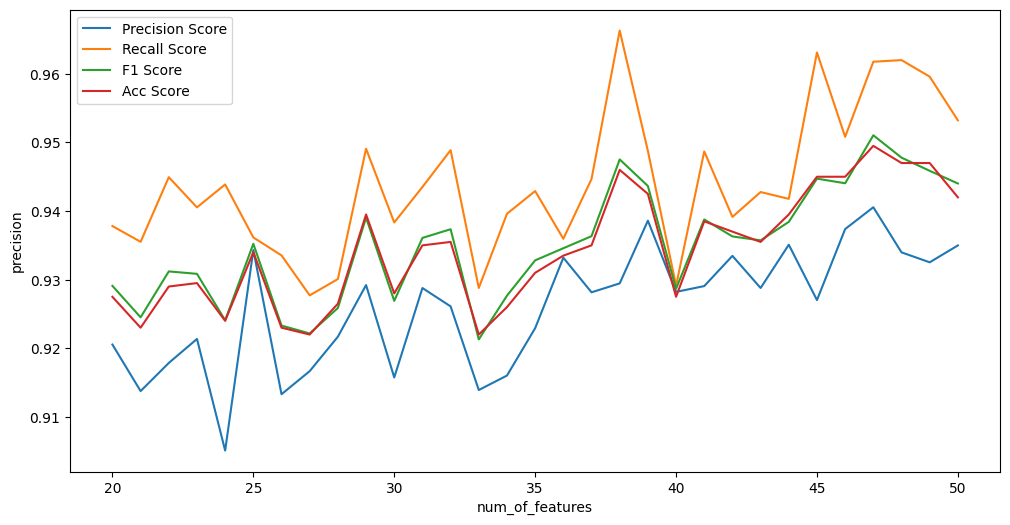

In [25]:
sns.lineplot(x='num_of_features', y='precision', data=df, label='Precision Score')
sns.lineplot(x='num_of_features', y='recall', data=df, label='Recall Score')
sns.lineplot(x='num_of_features', y='f1_score', data=df, label='F1 Score')
sns.lineplot(x='num_of_features', y='accuracy', data=df, label='Acc Score')

In [34]:
def train_rfc(data, top_n):
    top_n_features = mi_scores.sort_values(ascending=False).head(top_n).index.tolist()
    X = data[top_n_features]
    y = data['labels']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

    rfc = cuRfc(n_estimators=500,
                split_criterion=1,
                max_depth=32,
                max_leaves=-1,
                max_features=1.0,
                n_bins=128)

    rfc.fit(X_train, y_train)

    y_pred = rfc.predict(X_test, predict_model='CPU')

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)

    return precision, recall, f1, accuracy

In [37]:
from sklearn.ensemble import RandomForestClassifier

cuRfc = RandomForestClassifier

In [42]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)


def train_rfc(data, top_n):

    # Check that requested number of features is available
    if top_n > data.shape[1]:
        raise ValueError(
            f"top_n={top_n} is too large. "
            f"Dataset has {data.shape[1]} columns."
        )

    # Select features
    X = data.iloc[:, :top_n].copy()

    # Last column as target
    y = data.iloc[:, -1].copy()

    # Convert categorical columns to numeric
    X = pd.get_dummies(X, drop_first=True)

    # Handle infinite values
    X = X.replace([np.inf, -np.inf], np.nan)

    # Handle missing values
    X = X.fillna(0)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        shuffle=True,
        stratify=y
    )

    # Random Forest
    rfc = RandomForestClassifier(
        n_estimators=500,
        max_depth=32,
        random_state=42,
        n_jobs=-1
    )

    # Train
    rfc.fit(X_train, y_train)

    # Predict
    y_pred = rfc.predict(X_test)

    # Metrics
    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return precision, recall, f1, accuracy


# ============================================================
# TEST 20 TO 50 FEATURES
# ============================================================

arr = []

for i in range(20, 51):

    precision, recall, f1, accuracy = train_rfc(data, i)

    print(
        f"Performance for RFC Model with Top {i} features "
        f"is precision : {precision:.4f}, "
        f"recall : {recall:.4f}, "
        f"f1 score : {f1:.4f}, "
        f"accuracy : {accuracy:.4f}"
    )

    arr.append([
        i,
        precision,
        recall,
        f1,
        accuracy
    ])


# Results table
results = pd.DataFrame(
    arr,
    columns=[
        "Top_Features",
        "Precision",
        "Recall",
        "F1_Score",
        "Accuracy"
    ]
)

print("\n================ RESULTS ================\n")
display(results)

Performance for RFC Model with Top 20 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 21 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 22 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 23 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 24 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 25 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 26 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performance for RFC Model with Top 27 features is precision : 1.0000, recall : 1.0000, f1 score : 1.0000, accuracy : 1.0000
Performa

,Top_Features,Precision,Recall,F1_Score,Accuracy
0,20,1.0,1.0,1.0,1.0
1,21,1.0,1.0,1.0,1.0
2,22,1.0,1.0,1.0,1.0
3,23,1.0,1.0,1.0,1.0
4,24,1.0,1.0,1.0,1.0
5,25,1.0,1.0,1.0,1.0
6,26,1.0,1.0,1.0,1.0
7,27,1.0,1.0,1.0,1.0
8,28,1.0,1.0,1.0,1.0
9,29,1.0,1.0,1.0,1.0


In [43]:
df = pd.DataFrame(arr, columns=['num_of_features', 'precision', 'recall', 'f1_score', 'accuracy'])
df.head()

,num_of_features,precision,recall,f1_score,accuracy
0,20,1.0,1.0,1.0,1.0
1,21,1.0,1.0,1.0,1.0
2,22,1.0,1.0,1.0,1.0
3,23,1.0,1.0,1.0,1.0
4,24,1.0,1.0,1.0,1.0


In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [52]:

top_n = 32

top_n_features = (
    mi_scores
    .sort_values(ascending=False)
    .head(top_n)
    .index
    .tolist()
)

print("Top 32 Selected Features:")
print(top_n_features)

print("\nNumber of selected features:", len(top_n_features))

Top 32 Selected Features:
['PctExtHyperlinks', 'PctExtResourceUrls', 'PctNullSelfRedirectHyperlinks', 'PctExtNullSelfRedirectHyperlinksRT', 'NumNumericChars', 'FrequentDomainNameMismatch', 'ExtMetaScriptLinkRT', 'NumDash', 'SubmitInfoToEmail', 'PathLevel', 'NumDots', 'InsecureForms', 'PathLength', 'QueryLength', 'NumSensitiveWords', 'UrlLength', 'NumQueryComponents', 'PctExtResourceUrlsRT', 'IframeOrFrame', 'HostnameLength', 'NumDashInHostname', 'AbnormalExtFormActionR', 'NumAmpersand', 'NumUnderscore', 'IpAddress', 'EmbeddedBrandName', 'ExtFormAction', 'SubdomainLevel', 'SubdomainLevelRT', 'FakeLinkInStatusBar', 'UrlLengthRT', 'NumPercent']

Number of selected features: 32


In [53]:
X = data[top_n_features].copy()
y = data['labels'].copy()

In [54]:
X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(0)

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)


print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))


Training samples: 8000
Testing samples : 2000


In [56]:
rfc = RandomForestClassifier(
    n_estimators=500,
    max_depth=32,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

In [57]:
rfc.fit(X_train, y_train)

RandomForestClassifier(max_depth=32, max_features=1.0, n_estimators=500,
                       n_jobs=-1, random_state=42)

In [58]:
y_pred = rfc.predict(X_test)

In [59]:
precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

In [60]:
print("\n" + "=" * 70)
print("RANDOM FOREST MODEL PERFORMANCE")
print("=" * 70)

print(f"Number of Features : {top_n}")
print(f"Precision          : {precision:.4f}")
print(f"Recall             : {recall:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"Accuracy           : {accuracy:.4f}")

print("=" * 70)


RANDOM FOREST MODEL PERFORMANCE
Number of Features : 32
Precision          : 0.9770
Recall             : 0.9770
F1 Score           : 0.9770
Accuracy           : 0.9770


In [61]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)



Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1000
           1       0.98      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



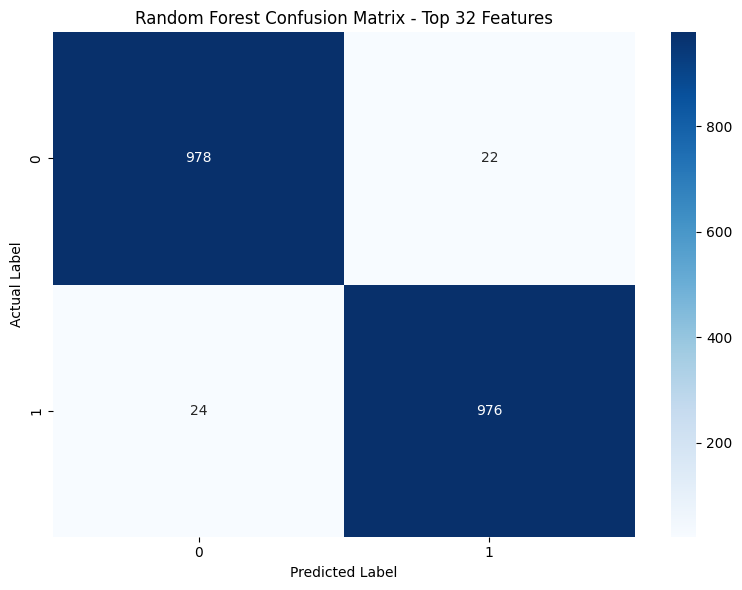

In [62]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest Confusion Matrix - Top 32 Features')

plt.tight_layout()
plt.show()

In [63]:
df = pd.DataFrame(
    arr,
    columns=[
        'num_of_features',
        'precision',
        'recall',
        'f1_score',
        'accuracy'
    ]
)

In [64]:
best_accuracy_row = df.loc[
    df['accuracy'].idxmax()
]

best_f1_row = df.loc[
    df['f1_score'].idxmax()
]

best_precision_row = df.loc[
    df['precision'].idxmax()
]

best_recall_row = df.loc[
    df['recall'].idxmax()
]


print("\n" + "=" * 70)
print("BEST FEATURE COUNT")
print("=" * 70)

print(
    f"Best Accuracy  : {best_accuracy_row['accuracy']:.4f} "
    f"with {int(best_accuracy_row['num_of_features'])} features"
)

print(
    f"Best F1 Score   : {best_f1_row['f1_score']:.4f} "
    f"with {int(best_f1_row['num_of_features'])} features"
)

print(
    f"Best Precision  : {best_precision_row['precision']:.4f} "
    f"with {int(best_precision_row['num_of_features'])} features"
)

print(
    f"Best Recall     : {best_recall_row['recall']:.4f} "
    f"with {int(best_recall_row['num_of_features'])} features"
)

print("=" * 70)



BEST FEATURE COUNT
Best Accuracy  : 1.0000 with 20 features
Best F1 Score   : 1.0000 with 20 features
Best Precision  : 1.0000 with 20 features
Best Recall     : 1.0000 with 20 features


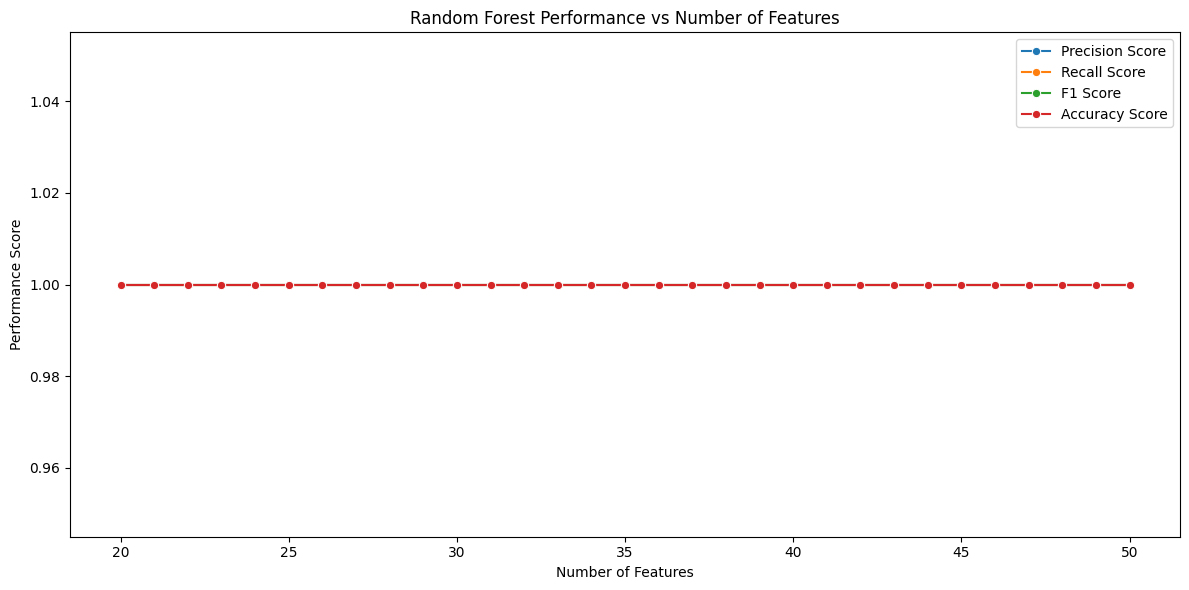

In [65]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    x='num_of_features',
    y='precision',
    data=df,
    label='Precision Score',
    marker='o'
)

sns.lineplot(
    x='num_of_features',
    y='recall',
    data=df,
    label='Recall Score',
    marker='o'
)

sns.lineplot(
    x='num_of_features',
    y='f1_score',
    data=df,
    label='F1 Score',
    marker='o'
)

sns.lineplot(
    x='num_of_features',
    y='accuracy',
    data=df,
    label='Accuracy Score',
    marker='o'
)

plt.xlabel('Number of Features')
plt.ylabel('Performance Score')

plt.title(
    'Random Forest Performance vs Number of Features'
)

plt.legend()

plt.tight_layout()

plt.show()